In [2]:
import tensorflow as tf 
import pandas as pd 
import numpy as np 
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [3]:
column_names = ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 
                'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

# Load data with pd.read_csv()
# Hint: Use the 'names' parameter to add column names
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"
df = pd.read_csv(url,names=column_names)


In [4]:
df.isna().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

In [5]:
(df.astype(str) == '?').any()

age         False
sex         False
cp          False
trestbps    False
chol        False
fbs         False
restecg     False
thalach     False
exang       False
oldpeak     False
slope       False
ca           True
thal         True
target      False
dtype: bool

In [6]:
df[['ca','thal']].replace('?',np.nan,inplace=True)

/var/folders/pz/82_6wg3s3jngvml3zjpsjgdh0000gn/T/ipykernel_59576/3200225564.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df[['ca','thal']].replace('?',np.nan,inplace=True)


,ca,thal
0,0.0,6.0
1,3.0,3.0
2,2.0,7.0
3,0.0,3.0
4,0.0,3.0
...,...,...
298,0.0,7.0
299,2.0,7.0
300,1.0,7.0
301,1.0,3.0


In [7]:
for col in df.columns:
    df[col] = pd.to_numeric(df[col],errors='coerce')

In [8]:
df.isnull().sum()

age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64

In [9]:
df = df.dropna()

In [10]:
df['target'] = (df['target'] > 0).astype(int)

In [11]:
df.target.value_counts()

target
0    160
1    137
Name: count, dtype: int64

In [12]:
df['target'].value_counts()

target
0    160
1    137
Name: count, dtype: int64

In [13]:
# df.isna().sum()

In [14]:
X = df.drop('target', axis=1).values
y = df['target'].values

In [15]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=67,stratify=y)

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 297 entries, 0 to 301
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       297 non-null    float64
 1   sex       297 non-null    float64
 2   cp        297 non-null    float64
 3   trestbps  297 non-null    float64
 4   chol      297 non-null    float64
 5   fbs       297 non-null    float64
 6   restecg   297 non-null    float64
 7   thalach   297 non-null    float64
 8   exang     297 non-null    float64
 9   oldpeak   297 non-null    float64
 10  slope     297 non-null    float64
 11  ca        297 non-null    float64
 12  thal      297 non-null    float64
 13  target    297 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 34.8 KB


In [17]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [18]:
baseline_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(13,)),
    tf.keras.layers.Dense(16,activation='relu'),
    tf.keras.layers.Dense(8,activation='relu'),
    tf.keras.layers.Dense(1,activation='sigmoid'),
])
baseline_model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])
baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 369 (1.44 KB)

 Trainable params: 369 (1.44 KB)

 Non-trainable params: 0 (0.00 B)

In [19]:
history_baseline = baseline_model.fit(
    X_train_s, y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.5291 - loss: 0.6921 - val_accuracy: 0.5000 - val_loss: 0.7004
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5820 - loss: 0.6705 - val_accuracy: 0.5833 - val_loss: 0.6810
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6349 - loss: 0.6528 - val_accuracy: 0.6250 - val_loss: 0.6646
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6561 - loss: 0.6351 - val_accuracy: 0.6875 - val_loss: 0.6507
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6931 - loss: 0.6201 - val_accuracy: 0.7292 - val_loss: 0.6373
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7354 - loss: 0.6053 - val_accuracy: 0.7708 - val_loss: 0.6236
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7513 - loss: 0.5923 - val_accuracy: 0.7500 - val_loss: 0.6102
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7619 - loss: 0.5782 - val_accuracy: 0.7500 - val_loss: 0.5974

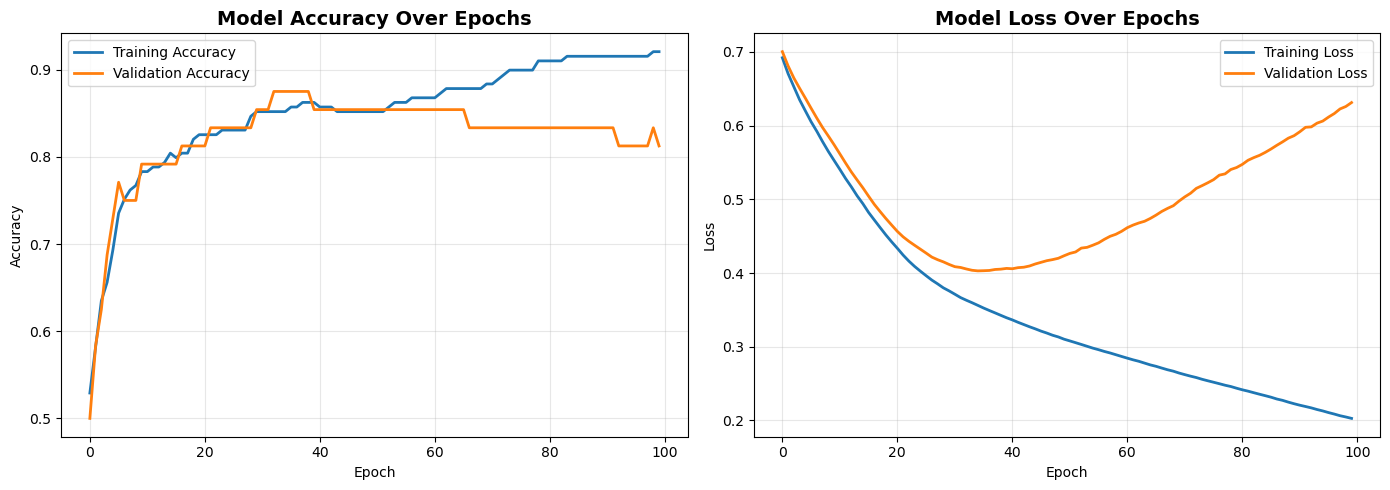


Final Training Accuracy: 0.9206
Final Validation Accuracy: 0.8125
Accuracy Gap: 0.1081

 Signs of overfitting detected! (gap > 5%)


In [20]:
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_baseline.history['accuracy'], label='Training Accuracy', linewidth=2)
plt.plot(history_baseline.history['val_accuracy'], label='Validation Accuracy', linewidth=2)
plt.title('Model Accuracy Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_baseline.history['loss'], label='Training Loss', linewidth=2)
plt.plot(history_baseline.history['val_loss'], label='Validation Loss', linewidth=2)
plt.title('Model Loss Over Epochs', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

final_train_acc = history_baseline.history['accuracy'][-1]
final_val_acc = history_baseline.history['val_accuracy'][-1]
gap = final_train_acc - final_val_acc

print(f"\nFinal Training Accuracy: {final_train_acc:.4f}")
print(f"Final Validation Accuracy: {final_val_acc:.4f}")
print(f"Accuracy Gap: {gap:.4f}")

if gap > 0.05:
    print("\n Signs of overfitting detected! (gap > 5%)")
else:
    print("\n Model is generalizing well!")

In [21]:
test_loss, test_acc = baseline_model.evaluate(X_test_s, y_test, verbose=0)
test_loss,test_acc

(0.47191670536994934, 0.8166666626930237)

In [22]:
y_pred_prob = baseline_model.predict(X_test_s)
# y_pred = (y_pred_prob > 0.5).astype(int).flatten()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step


In [23]:
# y_pred = np.argmax(y_pred_prob,axis=1)
y_pred = (y_pred_prob >= 0.5).astype(int).ravel()

In [24]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report

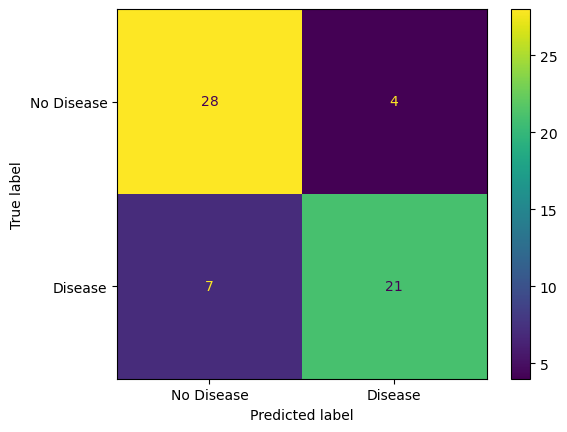

In [25]:
ConfusionMatrixDisplay.from_predictions(y_test,y_pred,display_labels=['No Disease','Disease'])

In [26]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.80      0.88      0.84        32
           1       0.84      0.75      0.79        28

    accuracy                           0.82        60
   macro avg       0.82      0.81      0.81        60
weighted avg       0.82      0.82      0.82        60



In [27]:
dropout_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(13,)),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(16, activation='relu'),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
], name='Dropout_Model')

# Compile
dropout_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Summary
dropout_model.summary()

Model: "Dropout_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

In [28]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

history_dropout = dropout_model.fit(
    X_train_s, y_train,
    epochs=200,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.4815 - loss: 0.7929 - val_accuracy: 0.4792 - val_loss: 0.7569
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5661 - loss: 0.7034 - val_accuracy: 0.5833 - val_loss: 0.7174
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5661 - loss: 0.6925 - val_accuracy: 0.6458 - val_loss: 0.6818
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5661 - loss: 0.7019 - val_accuracy: 0.7083 - val_loss: 0.6494
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6878 - loss: 0.6350 - val_accuracy: 0.7708 - val_loss: 0.6218
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.5873 - loss: 0.6351 - val_accuracy: 0.7708 - val_loss: 0.5968
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6614 - loss: 0.6219 - val_accuracy: 0.8125 - val_loss: 0.5739
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6878 - loss: 0.5775 - val_accuracy: 0.8333 - val_loss: 0.5543

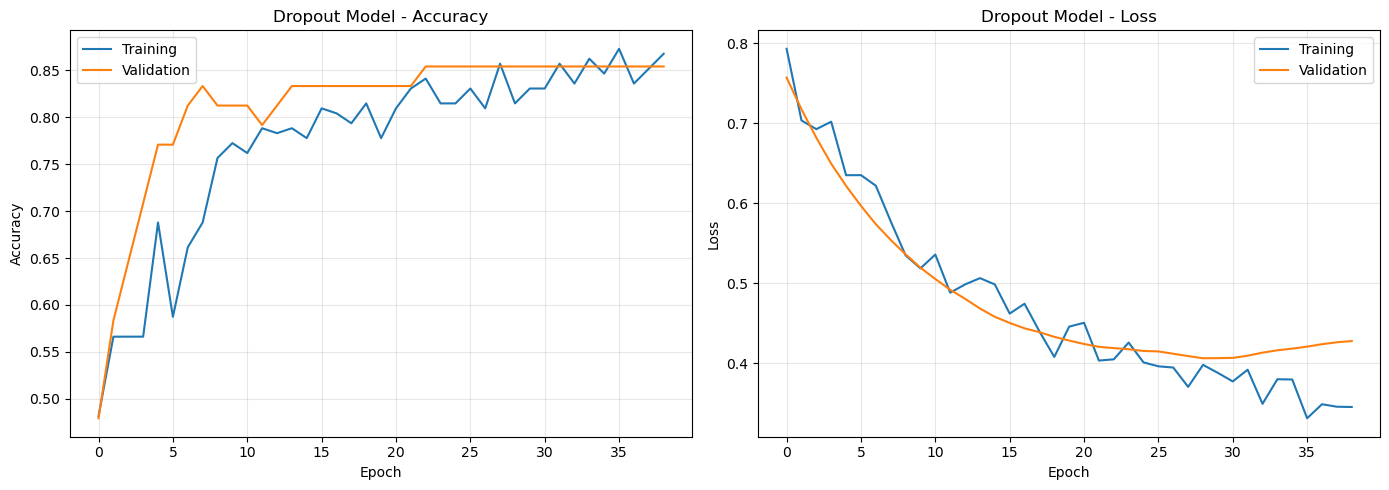


Model Comparison:
Baseline Model - Test Accuracy: 0.8167
Dropout Model  - Test Accuracy: 0.8333
Improvement: 0.0167

Dropout improved performance!


In [29]:
# Visualize
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history_dropout.history['accuracy'], label='Training')
plt.plot(history_dropout.history['val_accuracy'], label='Validation')
plt.title('Dropout Model - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history_dropout.history['loss'], label='Training')
plt.plot(history_dropout.history['val_loss'], label='Validation')
plt.title('Dropout Model - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Evaluate
test_loss_dropout, test_acc_dropout = dropout_model.evaluate(X_test_s, y_test, verbose=0)

# Compare
print("\nModel Comparison:")
print("=" * 50)
print(f"Baseline Model - Test Accuracy: {test_acc:.4f}")
print(f"Dropout Model  - Test Accuracy: {test_acc_dropout:.4f}")
print(f"Improvement: {(test_acc_dropout - test_acc):.4f}")

if test_acc_dropout > test_acc:
    print("\nDropout improved performance!")
else:
    print("\nBaseline was better (but Dropout may help prevent overfitting)")

In [30]:
bn_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(13,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(1, activation='sigmoid')
], name='BatchNorm_Model')

bn_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

bn_model.summary()

Model: "BatchNorm_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 64)             │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,393 (13.25 KB)

 Trainable params: 3,201 (12.50 KB)

 Non-trainable params: 192 (768.00 B)

In [31]:
# Create callbacks
lr_scheduler = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=5,
    min_lr=0.00001,
    verbose=1
)

early_stop_bn = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True,
    verbose=1
)

# Train
history_bn = bn_model.fit(
    X_train_s, y_train,
    epochs=150,
    batch_size=32,
    validation_split=0.2,
    callbacks=[lr_scheduler, early_stop_bn],
    verbose=1
)

Epoch 1/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.5503 - loss: 0.7890 - val_accuracy: 0.5833 - val_loss: 0.6939 - learning_rate: 0.0010
Epoch 2/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.6561 - loss: 0.7158 - val_accuracy: 0.6250 - val_loss: 0.6464 - learning_rate: 0.0010
Epoch 3/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7302 - loss: 0.5783 - val_accuracy: 0.7083 - val_loss: 0.6101 - learning_rate: 0.0010
Epoch 4/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7302 - loss: 0.5798 - val_accuracy: 0.7500 - val_loss: 0.5808 - learning_rate: 0.0010
Epoch 5/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7354 - loss: 0.5093 - val_accuracy: 0.7917 - val_loss: 0.5576 - learning_rate: 0.0010
Epoch 6/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7725 - loss: 0.4913 - val_accuracy: 0.8125 - val_loss: 0.5375 - learning_rate: 0.0010
Epoch 7/150
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7937 - loss: 0.5209 - val_accuracy: 0.8333

Training with different optimizers...

✓ SGD complete
✓ RMSprop complete
✓ Adam complete


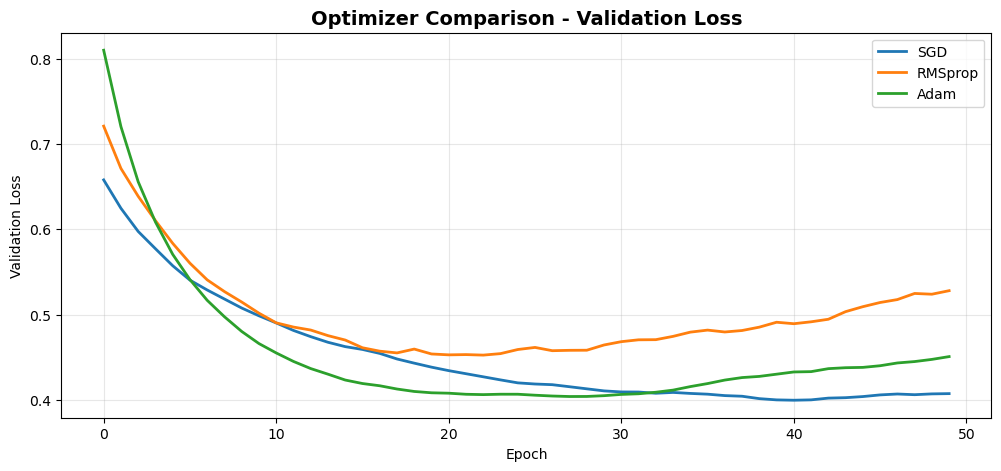


Final Validation Accuracies:
SGD:     0.8542
RMSprop: 0.8542
Adam:    0.8542

Best Optimizer: SGD with 0.8542 accuracy


In [32]:
# Function to build and train model with specific optimizer
def train_with_optimizer(optimizer_name, optimizer, model_name):
    # Build model
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(13,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.BatchNormalization(),
        tf.keras.layers.Dropout(0.3),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])
    
    model.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])
    
    # Train
    history = model.fit(
        X_train_s, y_train,
        epochs=50,
        batch_size=32,
        validation_split=0.2,
        verbose=0
    )
    
    return history, model

# Train with each optimizer
print("Training with different optimizers...\n")

hist_sgd, model_sgd = train_with_optimizer('SGD', tf.keras.optimizers.SGD(learning_rate=0.01), 'SGD_Model')
print("✓ SGD complete")

hist_rmsprop, model_rmsprop = train_with_optimizer('RMSprop', tf.keras.optimizers.RMSprop(learning_rate=0.001), 'RMSprop_Model')
print("✓ RMSprop complete")

hist_adam, model_adam = train_with_optimizer('Adam', tf.keras.optimizers.Adam(learning_rate=0.001), 'Adam_Model')
print("✓ Adam complete")

# Compare results
plt.figure(figsize=(12, 5))
plt.plot(hist_sgd.history['val_loss'], label='SGD', linewidth=2)
plt.plot(hist_rmsprop.history['val_loss'], label='RMSprop', linewidth=2)
plt.plot(hist_adam.history['val_loss'], label='Adam', linewidth=2)
plt.title('Optimizer Comparison - Validation Loss', fontsize=14, fontweight='bold')
plt.xlabel('Epoch')
plt.ylabel('Validation Loss')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# Final accuracies
print("\nFinal Validation Accuracies:")
print("=" * 40)
print(f"SGD:     {hist_sgd.history['val_accuracy'][-1]:.4f}")
print(f"RMSprop: {hist_rmsprop.history['val_accuracy'][-1]:.4f}")
print(f"Adam:    {hist_adam.history['val_accuracy'][-1]:.4f}")

best_optimizer = max(
    [('SGD', hist_sgd.history['val_accuracy'][-1]),
     ('RMSprop', hist_rmsprop.history['val_accuracy'][-1]),
     ('Adam', hist_adam.history['val_accuracy'][-1])],
    key=lambda x: x[1]
)
print(f"\nBest Optimizer: {best_optimizer[0]} with {best_optimizer[1]:.4f} accuracy")

### Functional API

In [33]:
import tensorflow.keras as tf

In [53]:
df['target'].value_counts()

target
0    160
1    137
Name: count, dtype: int64

In [55]:
# df.head()

In [51]:
input_ = tf.layers.Input(shape=(13,))
hidden1 = tf.layers.Dense(30,activation='relu')(input_)
hidden2 = tf.layers.Dense(30,activation='relu')(hidden1)
output = tf.layers.Dense(1,activation='sigmoid')(hidden2)
model = tf.Model(inputs=input_,outputs=output)
model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'])
history = model.fit(X_train_s,y_train,epochs=20,validation_data=(X_test_s,y_test))

Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.2700 - loss: 0.8138 - val_accuracy: 0.3500 - val_loss: 0.7743
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.3797 - loss: 0.7396 - val_accuracy: 0.4000 - val_loss: 0.7236
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5190 - loss: 0.6848 - val_accuracy: 0.5333 - val_loss: 0.6833
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6456 - loss: 0.6404 - val_accuracy: 0.5667 - val_loss: 0.6510
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7426 - loss: 0.6032 - val_accuracy: 0.6333 - val_loss: 0.6218
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7764 - loss: 0.5706 - val_accuracy: 0.7167 - val_loss: 0.5962
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7975 - loss: 0.5424 - val_accuracy: 0.7167 - val_loss: 0.5704
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7975 - loss: 0.5147 - val_accuracy: 0.7167 - val_loss: 0.5470
Epoch 9

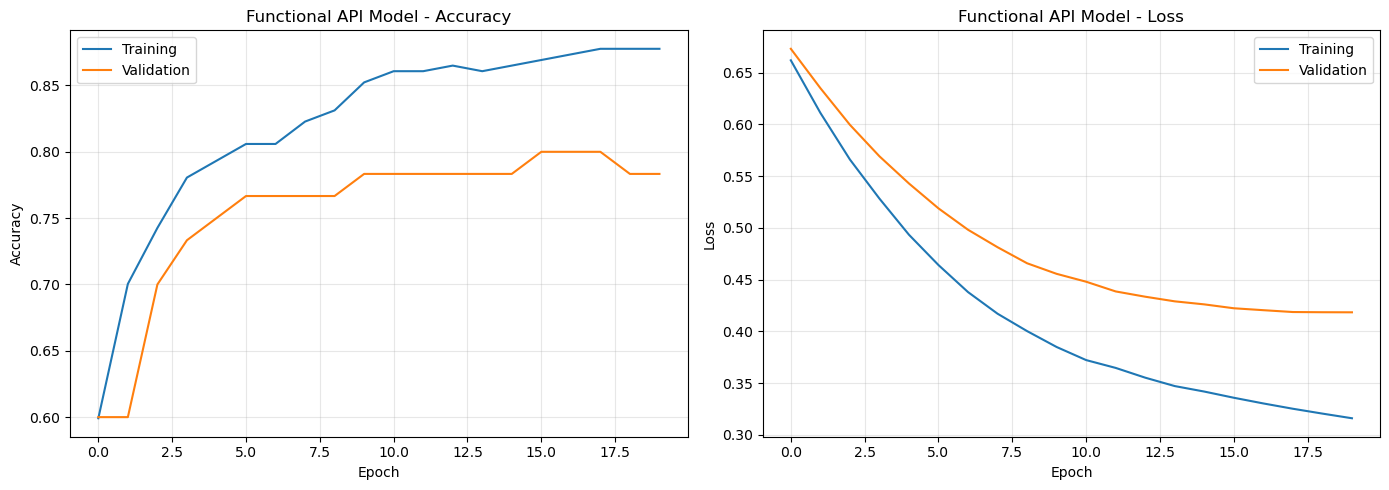


Model Comparison:
Baseline Model - Test Accuracy: 0.7833


In [35]:
# Visualize
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.title('Functional API Model - Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Training')
plt.plot(history.history['val_loss'], label='Validation')
plt.title('Functional API Model - Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Evaluate
test_loss, test_acc = model.evaluate(X_test_s, y_test, verbose=0)

# Compare
print("\nModel Comparison:")
print("=" * 50)
print(f"Baseline Model - Test Accuracy: {test_acc:.4f}")

### model saving and loading

In [36]:
model.save('../../00-data/api_model.keras')


In [37]:
import os
os.getcwd()

'/Users/subashanannair/Documents/00_forward/COHORTS/16_MARCH_2026/MicroCredential_2026/05_Deep_Learning/01_Neural_Network/06_Case_Studies'

In [40]:
loaded_model = tf.models.load_model('../../00-data/api_model.keras')

In [41]:
loaded_loss,loaded_acc = loaded_model.evaluate(X_test_s,y_test,verbose=2)

2/2 - 0s - 74ms/step - accuracy: 0.7833 - loss: 0.4185


In [57]:
y_pred_proba = loaded_model.predict(X_test_s[:1])
y_pred = (y_pred_proba>=0.5).astype(int).flatten()
print(y_pred)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
[1]


### model checkpoint

In [59]:
checkpoint = tf.callbacks.ModelCheckpoint(
    '../../00-data/model_checkpoint.keras',monitor='val_accuracy',save_best_only=True,mode='max',verbose=2
)
input_ = tf.layers.Input(shape=(13,))
hidden1 = tf.layers.Dense(30,activation='relu')(input_)
hidden2 = tf.layers.Dense(30,activation='relu')(hidden1)
output = tf.layers.Dense(1,activation='sigmoid')(hidden2)
cp_model = tf.Model(inputs=input_,outputs=output)
cp_model.compile(loss='binary_crossentropy',optimizer='adam',metrics=['accuracy'],)
history = cp_model.fit(X_train_s,y_train,epochs=20,validation_data=(X_test_s,y_test),
                       callbacks=[checkpoint])



Epoch 1/20
1/8 ━━━━━━━━━━━━━━━━━━━━ 3s 485ms/step - accuracy: 0.6562 - loss: 0.6638
Epoch 1: val_accuracy improved from None to 0.51667, saving model to model_checkpoint.keras

Epoch 1: finished saving model to model_checkpoint.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - accuracy: 0.5907 - loss: 0.6869 - val_accuracy: 0.5167 - val_loss: 0.6772
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.6686 - loss: 0.6307 
Epoch 2: val_accuracy improved from 0.51667 to 0.65000, saving model to model_checkpoint.keras

Epoch 2: finished saving model to model_checkpoint.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.6624 - loss: 0.6337 - val_accuracy: 0.6500 - val_loss: 0.6435
Epoch 3/20
1/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.6250 - loss: 0.6116
Epoch 3: val_accuracy improved from 0.65000 to 0.71667, saving model to model_checkpoint.keras

Epoch 3: finished saving model to model_checkpoint.keras
8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7637 - loss: 0.

In [62]:
cp_model= tf.models.load_model('../../00-data/model_checkpoint.keras')
loss,acc = cp_model.evaluate(X_test_s,y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8500 - loss: 0.3950  


### Keras tuner (hyper parameter)

In [63]:
import keras_tuner as kt


In [70]:
def build_model(hp):
    model = tf.Sequential()

    # input layer
    input_ = tf.layers.Input(shape=(13,))
    model.add(input_)
    # first layer tuning
    hp_unit_1 = hp.Choice('units_layer_1',values=[16,32,64,128])
    model.add(tf.layers.Dense(hp_unit_1,activation='relu'))

    # tune dropout rate
    hp_dropout = hp.Float('dropout_rate',min_value=0.0,max_value=0.5,step=0.1)
    model.add(tf.layers.Dropout(hp_dropout))

    # second layer tuning
    hp_unit_2 = hp.Choice('units_layer_2',values=[16,32,64,128])
    model.add(tf.layers.Dense(hp_unit_2,activation='relu'))

    # outputlayer
    model.add(tf.layers.Dense(1,activation='sigmoid'))

    # tune learning rate
    hp_lr = hp.Choice('learning_rate',values=[0.01,0.001,0.00001])

    model.compile(
        optimizer=tf.optimizers.Adam(learning_rate=hp_lr),
        loss='binary_crossentropy',metrics=['accuracy']
    )

    return model

In [71]:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,
    directory='heart_disease_tuning',
    project_name='heart_disease_tuning'
)
tuner.search_space_summary()

Reloading Tuner from heart_disease_tuning/heart_disease_tuning/tuner0.json
Search space summary
Default search space size: 4
units_layer_1 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128], 'ordered': True}
dropout_rate (Float)
{'default': 0.0, 'conditions': [], 'min_value': 0.0, 'max_value': 0.5, 'step': 0.1, 'sampling': 'linear'}
units_layer_2 (Choice)
{'default': 16, 'conditions': [], 'values': [16, 32, 64, 128], 'ordered': True}
learning_rate (Choice)
{'default': 0.01, 'conditions': [], 'values': [0.01, 0.001, 1e-05], 'ordered': True}


In [72]:
tuner.search(X_train_s,
             y_train,
             epochs=50,
             batch_size=32,
             validation_split=0.2,
             callbacks=[tf.callbacks.EarlyStopping(patience=5,
                                                   restore_best_weights=True)],
                                                   verbose=1)

Trial 10 Complete [00h 00m 01s]
val_accuracy: 0.875

Best val_accuracy So Far: 0.875
Total elapsed time: 00h 03m 51s


In [75]:
best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]

In [77]:
print(best_hps.get('units_layer_1'))
print(best_hps.get('units_layer_2'))
print(best_hps.get('dropout_rate'))
print(best_hps.get('learning_rate'))

64
128
0.2
0.001


### building and evaluating the best model

In [79]:
best_tuned_model = tuner.hypermodel.build(best_hps)
history_tuned = best_tuned_model.fit(
    X_train_s,y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
             callbacks=[tf.callbacks.EarlyStopping(patience=10,
                                                   restore_best_weights=True)],
                                                   verbose=1)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - accuracy: 0.6190 - loss: 0.6711 - val_accuracy: 0.8750 - val_loss: 0.5841
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7460 - loss: 0.5893 - val_accuracy: 0.8750 - val_loss: 0.4985
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8042 - loss: 0.5140 - val_accuracy: 0.8750 - val_loss: 0.4379
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8201 - loss: 0.4686 - val_accuracy: 0.8958 - val_loss: 0.3951
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8519 - loss: 0.4266 - val_accuracy: 0.8958 - val_loss: 0.3688
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.8519 - loss: 0.4009 - val_accuracy: 0.8958 - val_loss: 0.3507
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8571 - loss: 0.3750 - val_accuracy: 0.8958 - val_loss: 0.3421
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8307 - loss: 0.3779 - val_accuracy: 0.8958 - val_loss: 0.3369

In [80]:
loss,acc = best_tuned_model.evaluate(X_test_s,y_test)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8333 - loss: 0.3996
